In [6]:
import numpy as np
import torch
import torchvision.transforms as T
import os
import json
import glob
from tqdm.notebook import tqdm
import json
from PIL import Image
import pandas as pd 
from sklearn import svm

# Loading the Data

In this Section we will load the computed ImageNet100 embeddings from the Dinov2 model. This step has been completed and the embeddings should be in the "ImageNet100" folder oin the repository. To replicate the computation of the embeddings please follow the instructions in the README file. 

In [7]:
def load_embeddings(load_dir: str, embedding_type: str) -> dict:
    """
    Load specified type of embeddings and convert them to the desired nested dictionary format.
    
    Args:
        load_dir (str): Directory to load the embeddings from.
        embedding_type (str): Type of embedding to load ('class_tokens', 'patch_tokens', or 'register_tokens').
        
    Returns:
        dict: Dictionary where keys are filenames and values are the specified type of embeddings.
    """
    if embedding_type not in ['class_tokens', 'patch_tokens', 'register_tokens']:
        raise ValueError("Invalid embedding type. Must be 'class_tokens', 'patch_tokens', or 'register_tokens'.")

    # Load the metadata file to get the mapping of filenames to numpy files
    with open(os.path.join(load_dir, "metadata.json"), "r") as f:
        metadata = json.load(f)

    embeddings = {}
    for filename, npy_file in tqdm(metadata.items(), desc=f"Loading {embedding_type}"):
        # Load the numpy array
        loaded_embedding = np.load(os.path.join(load_dir, npy_file), allow_pickle=True).item()
        # Reconstruct the dictionary with the specified type of embedding
        embeddings[filename] = loaded_embedding[embedding_type]

    return embeddings

CLS tokens

In [8]:
train_dir = os.path.join(os.path.dirname(os.getcwd()), "Imagenet100", "train_embeddings")
train_embeddings_cls = load_embeddings(train_dir, "class_tokens")

val_dir = os.path.join(os.path.dirname(os.getcwd()), "Imagenet100", "val_embeddings")
val_embeddings_cls = load_embeddings(val_dir, "class_tokens")

Loading class_tokens:   0%|          | 0/9978 [00:00<?, ?it/s]

Loading class_tokens:   0%|          | 0/5000 [00:00<?, ?it/s]

Register Tokens 

In [9]:
train_dir = os.path.join(os.path.dirname(os.getcwd()), "Imagenet100", "train_embeddings")
train_embeddings_reg = load_embeddings(train_dir, "register_tokens")

val_dir = os.path.join(os.path.dirname(os.getcwd()), "Imagenet100", "val_embeddings")
val_embeddings_reg = load_embeddings(val_dir, "register_tokens")

Loading register_tokens:   0%|          | 0/9978 [00:00<?, ?it/s]

Loading register_tokens:   0%|          | 0/5000 [00:00<?, ?it/s]

Retrieve Labels

In [10]:
# Load the labels mapping
cwd = os.path.dirname(os.getcwd())
imagenet_folder= "Imagenet100"
labels_file= "Labels.json"
with open(os.path.join(cwd, imagenet_folder, labels_file)) as f:
    labels_mapping = json.load(f)

# Classification on Single Token 

In this section we will train a Neural Network Model to classify the images given the token embedding. <br>
The Classification models will be create for each type of token, hence: CLS token and all 4 of the Register Tokens.

In [11]:
def extract_features_labels(embeddings, embedding_type, reg, second_embeddings_dict=None):
    X = []
    y = []
    for filename, embedding in embeddings.items():
        label_code = os.path.basename(os.path.dirname(filename))
        label = labels_mapping[label_code]
        
        if embedding_type == 'class_tokens':
            # Adjusting to extract the embedding correctly
            feature = np.array(embedding[0])
        elif embedding_type == 'register_tokens':
                feature = np.array(embedding[0][reg]) 
        else:
            raise ValueError("Invalid embedding type. Must be 'class_tokens' or 'register_tokens'.")
            
        X.append(feature)
        y.append(label_code)
    return np.array(X), np.array(y)

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from tqdm import trange


class SimpleNN(nn.Module):
    def __init__(self, input_size, num_classes, dropout_rate=0.5):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(128, num_classes)
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Function to train and evaluate the model
def train_and_evaluate_nn(train_embeddings, val_embeddings, labels_mapping, embedding_type='class_tokens', reg=0, epochs=100):
    # Extract features and labels
    X_train, y_train = extract_features_labels(train_embeddings, embedding_type, reg)
    X_val, y_val = extract_features_labels(val_embeddings, embedding_type, reg)

    # Convert data to PyTorch tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(LabelEncoder().fit_transform(y_train), dtype=torch.long)
    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_val = torch.tensor(LabelEncoder().fit_transform(y_val), dtype=torch.long)

    # Data loaders
    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)

    # Model initialization
    model = SimpleNN(X_train.shape[1], len(labels_mapping))
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)  # Added weight decay for L2 regularization

    # Training loop
    train_acc, val_acc = [0], [0]
    for epoch in trange(epochs):
        model.train()
        for data, target in train_loader:
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

        # Evaluation
        train_acc.append(evaluate_accuracy(model, train_loader))
        val_acc.append(evaluate_accuracy(model, val_loader))
    
    return train_acc, val_acc

def plot_accuracy(train_acc, val_acc, title):
    # Plotting
    plt.figure(figsize=(10, 5))
    plt.plot(train_acc, label='Train Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(title+ ' (max accuracy: '+str(max(val_acc)) +')')
    plt.legend()
    plt.grid(True)
    plt.show()
    
# Function to evaluate accuracy
def evaluate_accuracy(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, targets in data_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return correct / total

Training the Models

100%|██████████| 50/50 [00:16<00:00,  3.12it/s]


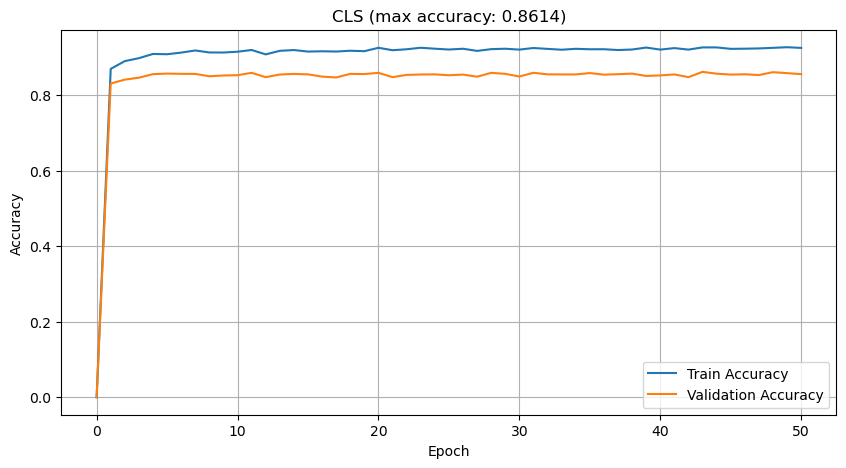

In [13]:
train_acc_cls, val_acc_cls= train_and_evaluate_nn(train_embeddings_cls, val_embeddings_cls, labels_mapping, embedding_type='class_tokens', epochs=50)
plot_accuracy(train_acc_cls, val_acc_cls, 'CLS')

100%|██████████| 50/50 [00:16<00:00,  3.12it/s]


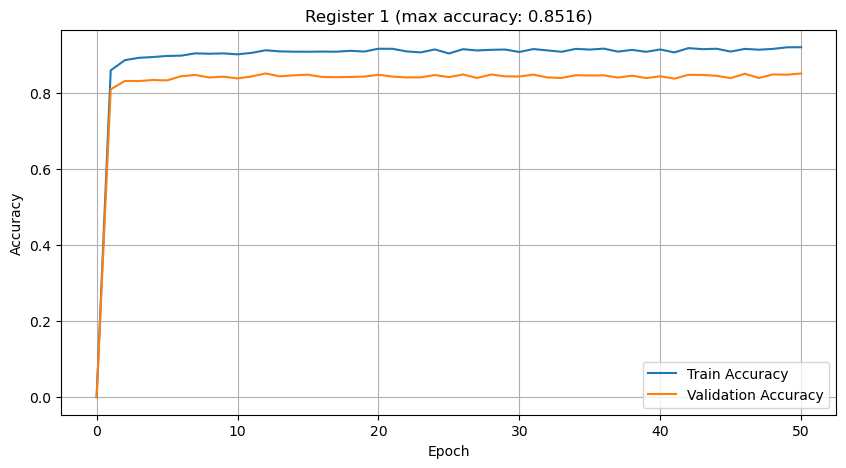

In [14]:
train_acc_reg, val_acc_reg= train_and_evaluate_nn(train_embeddings_reg, val_embeddings_reg, labels_mapping, embedding_type='register_tokens', epochs=50)
plot_accuracy(train_acc_reg, val_acc_reg, 'Register 1')

100%|██████████| 50/50 [01:19<00:00,  1.59s/it]


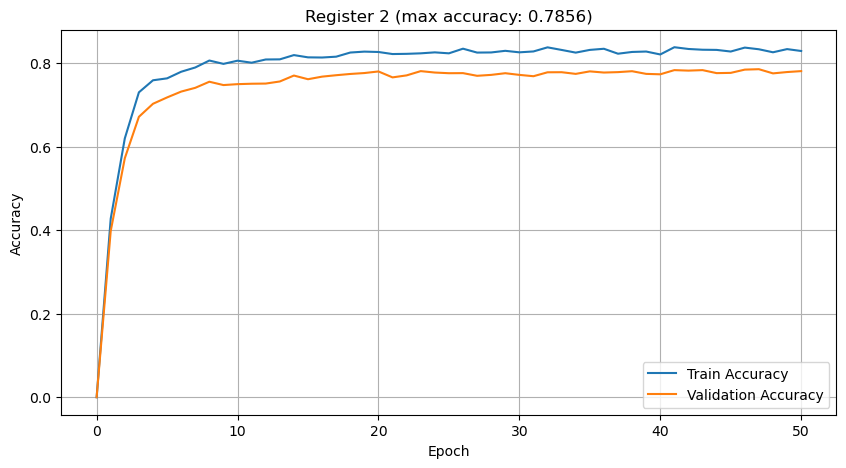

In [15]:
train_acc_reg, val_acc_reg= train_and_evaluate_nn(train_embeddings_reg, val_embeddings_reg, labels_mapping, embedding_type='register_tokens', reg=1, epochs=50)
plot_accuracy(train_acc_reg, val_acc_reg, 'Register 2')

100%|██████████| 50/50 [00:15<00:00,  3.19it/s]


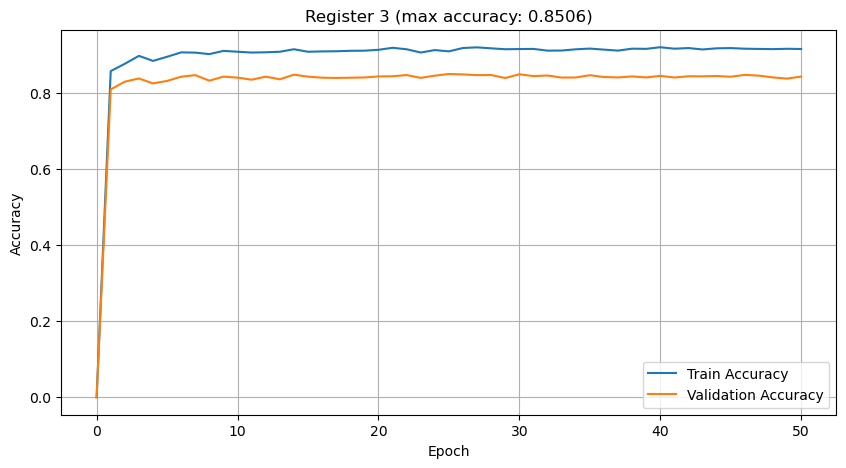

In [16]:
train_acc_reg, val_acc_reg= train_and_evaluate_nn(train_embeddings_reg, val_embeddings_reg, labels_mapping, embedding_type='register_tokens', reg=2, epochs=50)
plot_accuracy(train_acc_reg, val_acc_reg, 'Register 3')

100%|██████████| 50/50 [00:15<00:00,  3.14it/s]


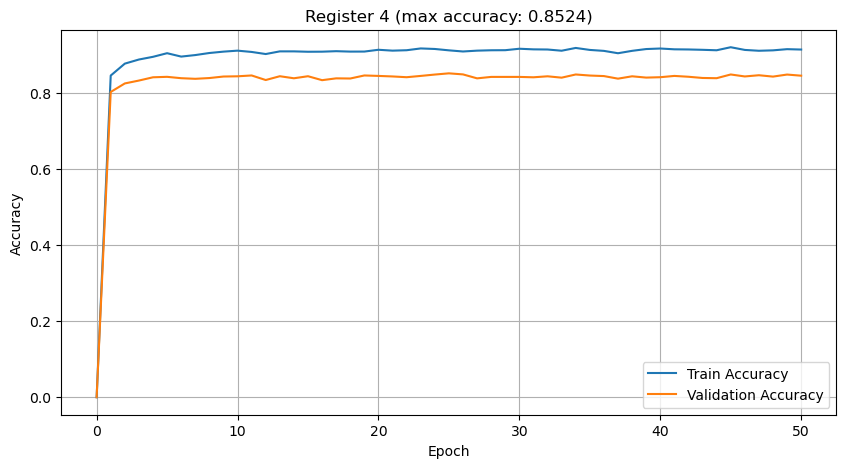

In [17]:
train_acc_reg, val_acc_reg= train_and_evaluate_nn(train_embeddings_reg, val_embeddings_reg, labels_mapping, embedding_type='register_tokens', reg=3, epochs=50)
plot_accuracy(train_acc_reg, val_acc_reg, 'Register 4')

# Predicting the CLS Token Using the Register Tokens

To try to understand the relation between the CLS token and the registers we build a Model aimed at predicting the CLS Token embedding given all 4 Register Tokens

In [18]:
def prepare_data(embeddings, embedding_type='class_tokens'):
    X = []
    y = []
    for filename, embedding in embeddings.items():
        if embedding_type == 'class_tokens':
            # Extracting the CLS token which is our label for prediction
            cls_token = np.array(embedding[0])
            y.append(cls_token)
        elif embedding_type == 'register_tokens':
            # Flattening and concatenating all register tokens to use as features
            registers = np.concatenate(embedding[0], axis=0)
            X.append(registers)
        else:
            raise ValueError("Invalid embedding type. Must be 'class_tokens' or 'register_tokens'.")

    return np.array(X), np.array(y)

# Prepare training and validation data
train_X, train_y = prepare_data(train_embeddings_reg, embedding_type='register_tokens')
val_X, val_y = prepare_data(val_embeddings_reg, embedding_type='register_tokens')

# Since 'class_tokens' are used as labels
_, train_labels = prepare_data(train_embeddings_cls, embedding_type='class_tokens')
_, val_labels = prepare_data(val_embeddings_cls, embedding_type='class_tokens')

# Converting data to tensors
train_data = torch.tensor(train_X, dtype=torch.float32)
train_labels = torch.tensor(train_labels, dtype=torch.float32)
val_data = torch.tensor(val_X, dtype=torch.float32)
val_labels = torch.tensor(val_labels, dtype=torch.float32)

In [19]:
class RegisterToCLSModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(RegisterToCLSModel, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, output_size)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def train_model(train_data, train_labels, val_data, val_labels, epochs=500, learning_rate=0.001):
    model = RegisterToCLSModel(train_data.shape[1], train_labels.shape[1])
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    train_loss_per_epoch= []
    val_loss_per_epoch= []
    for epoch in trange(epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(train_data)
        loss = criterion(outputs, train_labels)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_outputs = model(val_data)
            val_loss = criterion(val_outputs, val_labels)
            train_loss_per_epoch.append(loss.item())
            val_loss_per_epoch.append(val_loss.item())
#             print(f'Epoch {epoch+1}, Train Loss: {loss.item()}, Val Loss: {val_loss.item()}')
    return train_loss_per_epoch, val_loss_per_epoch

In [20]:
def plot_loss(train_loss, val_loss):
    # Plotting
    plt.figure(figsize=(10, 5))
    plt.plot(train_loss, label='Train Loss')
    plt.plot(val_loss, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Minimum Loss over Epochs: '+str(min(val_loss)))
    plt.legend()
    plt.grid(True)
    plt.show()

100%|██████████| 500/500 [00:23<00:00, 21.07it/s]


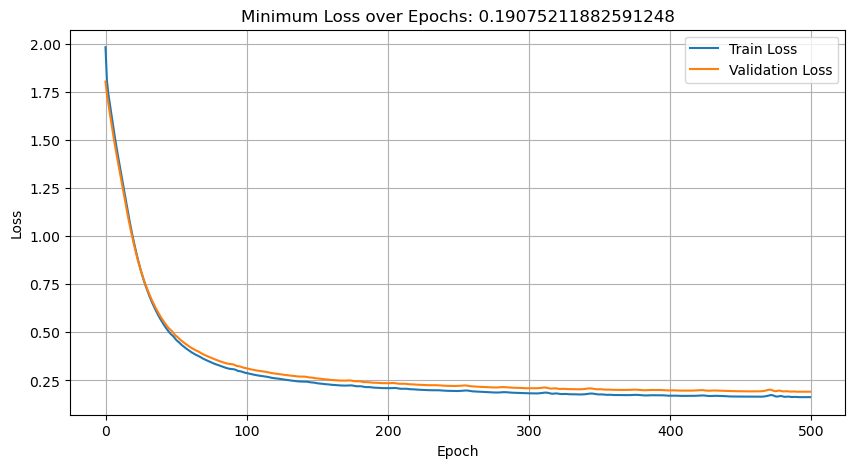

In [22]:
train_loss_per_epoch, val_loss_per_epoch= train_model(train_data, train_labels, val_data, val_labels)
plot_loss(train_loss_per_epoch, val_loss_per_epoch)

# Exploring the Registers

In this section we will be exploring the behavior of the Register Tokens as compared to the CLS Tokens. We already saw above that the Register Tokens behave suspiciously similar to the CLS Token, they are able to classify images with hogh accuracy and even predict the CLS token itself. 
In our exploration we aim to answer the question "Is there any unique information stored in the Registers?"

### Euclidean Distance

We calculate and present the euclidean distances between the CLS Token and each of the Register Tokens

Calculating Euclidean distances: 100%|██████████| 9978/9978 [00:05<00:00, 1941.19it/s]


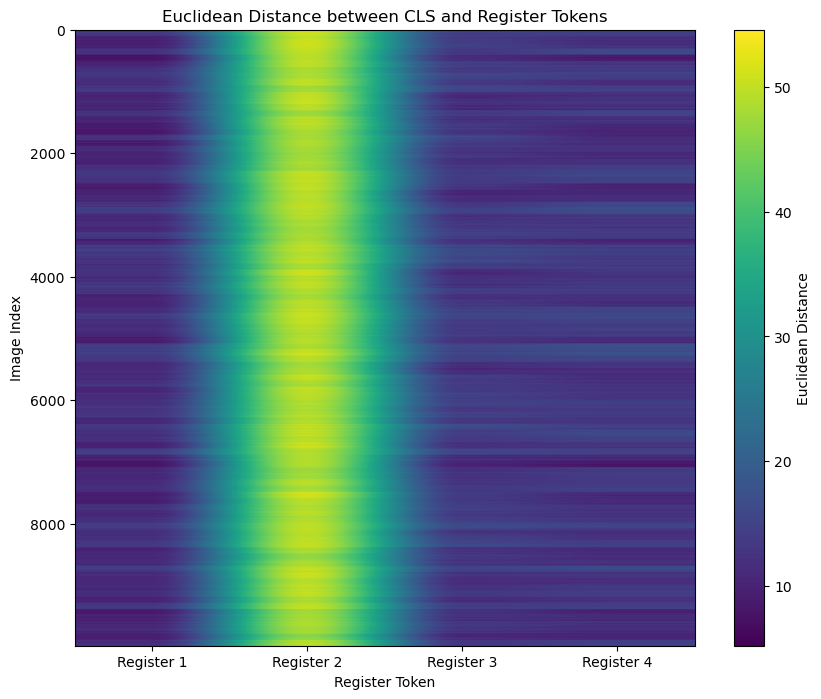

In [36]:
from sklearn.metrics.pairwise import euclidean_distances
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

def calculate_distances(cls_embeddings, reg_embeddings):
    # Initialize a list to store Euclidean distances for each image and each register token
    all_distances = []

    # Iterate over each image and compute distances
    for filename, cls_emb in tqdm(cls_embeddings.items(), desc="Calculating Euclidean distances"):
        cls_token = np.array(cls_emb[0]).reshape(1, -1)  # Reshape CLS token for distance calculation
        reg_emb = reg_embeddings[filename][0]
        
        # Calculate distances to each register token
        im_distances = []
        for reg_idx in range(4):  # Assuming there are exactly 4 registers per image
            reg_token = np.array(reg_emb[reg_idx]).reshape(1, -1)
            distance = euclidean_distances(cls_token, reg_token)[0][0]  # Compute Euclidean distance
            im_distances.append(distance)
        all_distances.append(im_distances)
    
    return np.array(all_distances)

def plot_distance_heatmap(distance_array):
    plt.figure(figsize=(10, 8))
    plt.imshow(distance_array, cmap='viridis', aspect='auto')
    plt.colorbar(label='Euclidean Distance')
    plt.title('Euclidean Distance between CLS and Register Tokens')
    plt.xlabel('Register Token')
    plt.ylabel('Image Index')
    plt.xticks(ticks=range(4), labels=[f'Register {i+1}' for i in range(4)])
    plt.show()

# Calculate and plot the Euclidean distances
distance_array = calculate_distances(train_embeddings_cls, train_embeddings_reg)
plot_distance_heatmap(distance_array)


### Cosine Similarity

To retrieve more detailed information about the differences between the tokens we explore their direction as well, below we show the calculation of the cosine similarity between the CLS Token and the Register Tokens. 

Calculating similarities:   0%|          | 0/9978 [00:00<?, ?it/s]

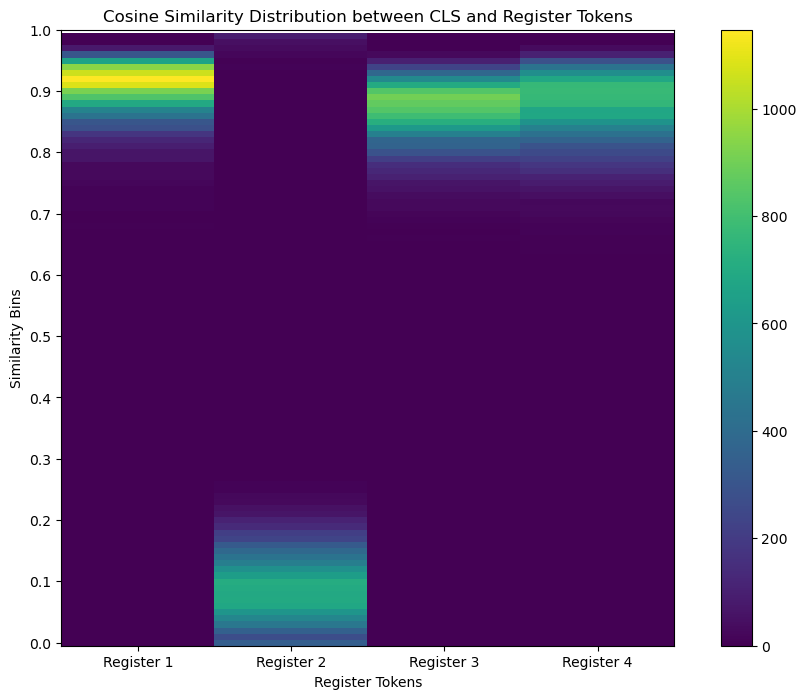

In [33]:
from sklearn.metrics.pairwise import cosine_similarity

def initialize_similarity_matrix(cls_embeddings, reg_embeddings):
    # Define the similarity matrix with dimensions 4x100
    similarity_matrix = np.zeros((4, 100))

    # Iterate over each image and compute similarities
    for filename, cls_emb in tqdm(cls_embeddings.items(), desc="Calculating similarities"):
        cls_token = np.array(cls_emb[0]).reshape(1, -1)  # Reshape CLS token for cosine similarity
        reg_emb = reg_embeddings[filename][0]
        for reg_idx in range(4):  # Assuming there are exactly 4 registers per image
            reg_token = np.array(reg_emb[reg_idx]).reshape(1, -1)
            similarity = cosine_similarity(cls_token, reg_token)[0][0]
            # Determine the bin for the similarity score
            bin_index = int(similarity * 100)
            bin_index = min(bin_index, 99)  # Ensure it does not go out of bounds
            # Increment the appropriate bin in the matrix
            similarity_matrix[reg_idx, bin_index] += 1

    return similarity_matrix

def plot_similarity_heatmap(similarity_matrix):
    fig, ax = plt.subplots(figsize=(12, 8))
    cax = ax.matshow(similarity_matrix.T, cmap='viridis', aspect=0.04)  # Manually adjust aspect ratio
    plt.title('Cosine Similarity Distribution between CLS and Register Tokens')
    plt.xlabel('Register Tokens')
    plt.ylabel('Similarity Bins')
    plt.colorbar(cax)
    ax.xaxis.set_ticks_position('bottom')  # Move x-axis to the bottom
    ax.invert_yaxis()  # Invert y-axis
    plt.xticks(range(4), [f'Register {i}' for i in range(1, 5)])
    plt.yticks(range(0, 101, 10), [f'{i/10:.1f}' for i in range(11)])
    plt.show()
    
similarity_matrix = initialize_similarity_matrix(train_embeddings_cls, train_embeddings_reg)
plot_similarity_heatmap(similarity_matrix)

It is clear from the calcualtions above that register 2 is different then the rest of the registers, potentially containing additional information that is not captured in the CLs Token. 

# Classification Model on CLS and Register 2 ( Concatenated)

As mentioned above, we discovered the orthogonal bahvior of Register 2 that varies greatly from the behavior of the rest of the Registers. Register 2 contains embedding values that are significantly different then those of the CLS token. This leads us to believe that there may be information stored in register 2 that could potentially enhance the performance of the model (in addition to the CLS token) if handled correctly. In this section we attempt to build a classification model, this time using a concatenation of the 2 tokens (CLS and Register 2).

In [23]:
def extract_features_labels(cls_embedding, reg_embedding):
    X_cls = []
    X_reg = []
    y = []
    for filename, embedding in cls_embedding.items():
        label_code = os.path.basename(os.path.dirname(filename))
        label = labels_mapping[label_code]
        feature = np.array(embedding[0])
        X_cls.append(feature)
        y.append(label_code)

    for filename, embedding in reg_embedding.items():
        feature = np.array(embedding[0][1])
        X_reg.append(feature)

    X_concat = [np.concatenate((cls_feat, reg_feat)) for cls_feat, reg_feat in zip(X_cls, X_reg)]
    return np.array(X_concat), np.array(y)

In [24]:
class SimpleNN(nn.Module):
    def __init__(self, input_size, num_classes, dropout_rate=0.5):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(128, num_classes)
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Function to train and evaluate the model
def train_and_evaluate_nn(cls_train_embeddings, cls_val_embeddings, reg_train_embeddings, reg_val_embeddings, labels_mapping, epochs=100):
    # Extract features and labels
    X_train, y_train = extract_features_labels(cls_train_embeddings, reg_train_embeddings)
    X_val, y_val = extract_features_labels(cls_val_embeddings, reg_val_embeddings)

    # Convert data to PyTorch tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(LabelEncoder().fit_transform(y_train), dtype=torch.long)
    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_val = torch.tensor(LabelEncoder().fit_transform(y_val), dtype=torch.long)

    # Data loaders
    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)

    # Model initialization
    model = SimpleNN(X_train.shape[1], len(labels_mapping))
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)  # Added weight decay for L2 regularization

    # Training loop
    train_acc, val_acc = [0], [0]
    for epoch in trange(epochs):
        model.train()
        for data, target in train_loader:
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()

        # Evaluation
        train_acc.append(evaluate_accuracy(model, train_loader))
        val_acc.append(evaluate_accuracy(model, val_loader))
    
    return train_acc, val_acc

def plot_accuracy(train_acc, val_acc, title):
    # Plotting
    plt.figure(figsize=(10, 5))
    plt.plot(train_acc, label='Train Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(title+ ' (max accuracy: '+str(max(val_acc)) +')')
    plt.legend()
    plt.grid(True)
    plt.show()
    
# Function to evaluate accuracy
def evaluate_accuracy(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, targets in data_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return correct / total


100%|██████████| 100/100 [03:04<00:00,  1.85s/it]


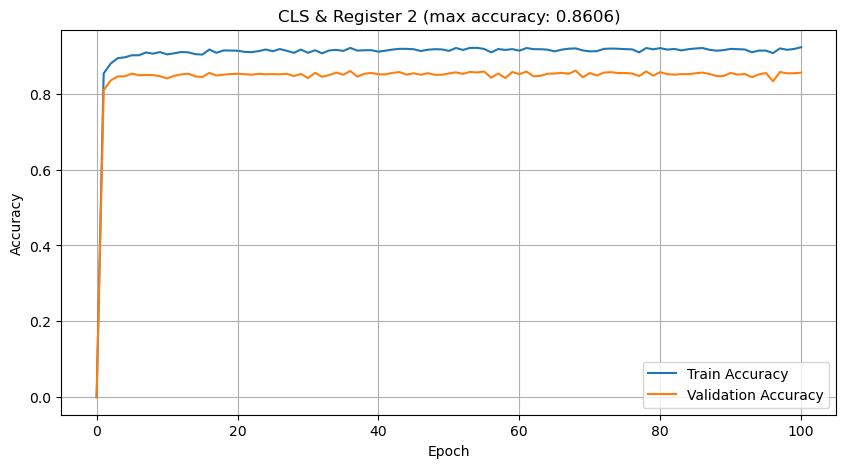

In [25]:
train_acc_cls_reg2, val_acc_cls_reg2= train_and_evaluate_nn(train_embeddings_cls, val_embeddings_cls, train_embeddings_reg, val_embeddings_reg, labels_mapping, epochs=100)
plot_accuracy(train_acc_cls_reg2, val_acc_cls_reg2, 'CLS & Register 2')

The model did not exceed the performance of the original classification model built on the CLS Token alone. Our Hypothesis is that since the Dinov2 model is trained on ImageNet the CLS Token captures the global information of the image quite well, and although Register 2 contains additional information, it is uneccessary here. Hence, If we were to replicate this study on another dataset, say COCO2014 or COCO2017 (Object Detection datasets)- adding Register 2 would in fact enhance the performance of the model ;) 
See Notebook- "COCO2017"

# Appendices

In this section we attempted to create a classification model on the patch embeddings of the images and compare the performance of this model with the other models (Register Token Classification and CLS Token Classification). Unfortunately this was not successful as the model trained on the patch embeddings showed very poor performance (values that did not seem right to us...)

In [26]:
import random
# Initialize label encoder globally
label_encoder = LabelEncoder()

def batch_embedding_loader(load_dir: str, embedding_type: str, batch_size: int):
    """
    Generator to load embeddings in batches from the specified directory.
    
    Args:
        load_dir (str): Directory from which to load embeddings.
        embedding_type (str): Type of embedding to load ('class_tokens', 'patch_tokens', 'register_tokens').
        batch_size (int): Number of embeddings to load per batch.
    
    Yields:
        tuple: Two tensors, one with embeddings and one with labels, for each batch.
    """
    # Load metadata JSON
    with open(os.path.join(load_dir, "metadata.json"), "r") as f:
        metadata = json.load(f)

    # Load all labels for encoding
    all_labels = [os.path.basename(os.path.dirname(filename)) for filename in metadata.keys()]
    label_encoder.fit(all_labels)  # Fit label encoder based on all possible labels
    # Create a list of items and shuffle it
    items = list(metadata.items())
    random.shuffle(items)

    batch_features = []
    batch_labels = []

    for filename, npy_file in tqdm(items, desc=f"Loading {embedding_type}"):
        
        # Load the numpy array for the specific type of embeddings
        full_path = os.path.join(load_dir, npy_file)
        loaded_embedding = np.load(full_path, allow_pickle=True).item()
        embedding = loaded_embedding[embedding_type]
        
        # Flatten and convert to tensor
        tensor_embedding = torch.tensor(embedding, dtype=torch.float32).view(-1)
        batch_features.append(tensor_embedding)
        
        # Encode label
        label_code = os.path.basename(os.path.dirname(filename))
        encoded_label = label_encoder.transform([label_code])[0]
        batch_labels.append(encoded_label)

        if len(batch_features) == batch_size:
            # Yield a full batch
            yield torch.stack(batch_features), torch.tensor(batch_labels, dtype=torch.long)
            batch_features = []
            batch_labels = []

    if batch_features:
        # Yield the last batch if it exists
        yield torch.stack(batch_features), torch.tensor(batch_labels, dtype=torch.long)

# Usage
# Define directory and batch size
train_dir = os.path.join(os.getcwd(), "train_embeddings")
batch_size = 20  # Define suitable batch size

# Initialize generator for training data
train_generator = batch_embedding_loader(train_dir, "patch_tokens", batch_size)

In [27]:
class SimpleNN(nn.Module):
    def __init__(self, input_size, num_classes, dropout_rate=0.5):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 512)  
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(512, 128)
        self.fc3 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

In [28]:
def train_model(model, train_dir, val_dir, embedding_type, batch_size=64, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_acc_per_epoch = []
    val_acc_per_epoch = []

    for epoch in range(epochs):
        model.train()
        total_train = 0
        correct_train = 0
        train_generator = batch_embedding_loader(train_dir, embedding_type, batch_size)
        
        for train_features, train_labels in train_generator:
            train_features, train_labels = train_features.to(device), train_labels.to(device)
            optimizer.zero_grad()
            outputs = model(train_features)
            loss = criterion(outputs, train_labels)
            loss.backward()
            optimizer.step()

            _, predicted = torch.max(outputs.data, 1)
            total_train += train_labels.size(0)
            correct_train += (predicted == train_labels).sum().item()

        train_accuracy = 100 * correct_train / total_train
        train_acc_per_epoch.append(train_accuracy)

        # Validation loop
        model.eval()
        total_val = 0
        correct_val = 0
        val_generator = batch_embedding_loader(val_dir, embedding_type, batch_size)
        with torch.no_grad():
            for val_features, val_labels in val_generator:
                val_features, val_labels = val_features.to(device), val_labels.to(device)
                outputs = model(val_features)
                _, predicted = torch.max(outputs.data, 1)
                total_val += val_labels.size(0)
                correct_val += (predicted == val_labels).sum().item()

        val_accuracy = 100 * correct_val / total_val
        val_acc_per_epoch.append(val_accuracy)

        print(f'Epoch {epoch+1}/{epochs}, Train Accuracy: {train_accuracy}%, Validation Accuracy: {val_accuracy}%')

    return model, train_acc_per_epoch, val_acc_per_epoch


In [37]:
train_dir = os.path.join(os.path.dirname(os.getcwd()), "Imagenet100", "train_embeddings")
val_dir = os.path.join(os.path.dirname(os.getcwd()), "Imagenet100", "val_embeddings")

embedding_type = "patch_tokens"
batch_size = 20
epochs = 10
model = SimpleNN(input_size=98304, num_classes=100)

model, train_acc, val_acc = train_model(model, train_dir, val_dir, embedding_type, batch_size, epochs)

Loading patch_tokens: 100%|██████████| 5000/5000 [00:31<00:00, 159.76it/s]


Epoch 1/10, Train Accuracy: 4.710362798155943%, Validation Accuracy: 8.8%


Loading patch_tokens: 100%|██████████| 5000/5000 [00:32<00:00, 154.29it/s]


Epoch 2/10, Train Accuracy: 6.0633393465624374%, Validation Accuracy: 8.4%


Loading patch_tokens: 100%|██████████| 5000/5000 [00:30<00:00, 163.20it/s]


Epoch 3/10, Train Accuracy: 5.8929645219482865%, Validation Accuracy: 8.26%


... (10 outputs left out)

Loading patch_tokens: 100%|██████████| 5000/5000 [00:39<00:00, 127.33it/s]


Epoch 9/10, Train Accuracy: 5.451994387652836%, Validation Accuracy: 6.06%


Loading patch_tokens: 100%|██████████| 5000/5000 [00:31<00:00, 159.62it/s]

Epoch 10/10, Train Accuracy: 4.499899779514933%, Validation Accuracy: 5.58%


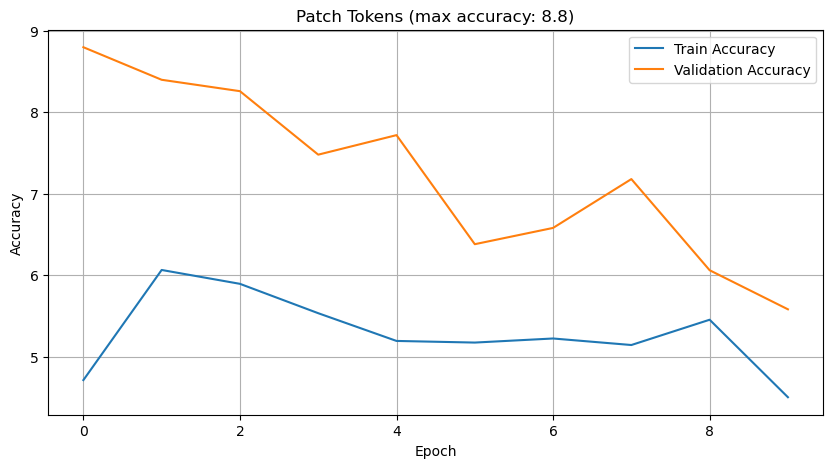

In [38]:
plot_accuracy(train_acc, val_acc, "Patch Tokens")